# Where the models look

> Integrated gradients of the Kex, CEC and Cs-137 ratio models on the same spectra, against the variation between seeds and the regions of the IAEA artefact

In [ ]:
import copy
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from fastai.torch_core import set_seed
from fastcore.test import *
from soilspecdata.all import load_ossl
from soilspecdl.all import get_splitter, spectral_learner, SpectralCNN, predict, regression_scores
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.transfer import preprocessings, load_pretrained, fuku_dls, model_dir
from ossl_fuku_transfer.importance import integrated_gradients, occlusion, region_shares

/Users/franckalbinet/aai-ws/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


The cells that read the Fukushima data are marked `#| fukudata`. The outputs on this page come from a local run.

In `20_grouped_cv`, the Cs-137 ratio is predictable on new fields (R² 0.52 to 0.57) and Kex barely (0.26 to 0.28). If the models that predict well rely on the same spectral regions, the regions point to what the spectra measure well. `17_importance` and `19_cs137_inside` computed importance profiles for Kex and for the Cs-137 ratio, each from one training run, with different models and spectra. This notebook puts the models on the same footing:

- One method: the mean absolute integrated gradient per wavenumber, scaled to sum to 1, as in `17_importance`.
- The same spectra: the Fukushima test spectra of the Cs-137 study's split for every model, and 2,000 OSSL validation spectra for the OSSL models.
- Three seeds for each model trained on Fukushima, so that a difference between models can be compared with the difference between seeds of one model.

The frozen block-4 ridge of `19_cs137_inside` is left out: its standardised features give large weights to quiet regions, which distorts the attributions.

## Data

The spectra after SNV and the first derivative. Kex and CEC on `log1p`, as in `03_kex` and `04_cec`, and the Cs-137 ratio as in `10_cs137`:

In [ ]:
#| fukudata
pipe = preprocessings()['snv_d1']
fuku = load_fuku()
ids = fuku.sample_ids
src = fuku.source.reindex(ids)
ratio = pd.concat([pd.read_csv(fuku_path()/'reference'/f'cs137_ratio_{s}.csv', usecols=['ID', 'exCs137_totalCs137']) for s in ('train', 'test')])
ratio = ratio.assign(ID=ratio.ID.astype(str)).set_index('ID')['exCs137_totalCs137']
yf = {'Kex': np.log1p(src['soil_ex_K2O'].to_numpy(dtype=float) / mg_k2o_per_cmolc), 'CEC': np.log1p(src['soil_CEC'].to_numpy(dtype=float)),
      'Cs-137 ratio': ratio.reindex(ids).to_numpy()}
Xf = pipe.fit_transform(fuku.spectra)
is_test = np.isin(ids, cs137_split()[1])
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
Xo, yo = {}, {}
for p, c in {'Kex': 'k.ext_usda.a725_cmolc.kg', 'CEC': 'cec_usda.a723_cmolc.kg'}.items():
    X, y, _ = om.xy(c)
    y = np.log1p(y.ravel())
    vs = np.random.default_rng(0).choice(get_splitter(0.9, 0.1, seed=42)(X, y)[1], 2000, replace=False)
    Xo[p], yo[p] = pipe.transform(X[vs]), y[vs]
{k: int((np.isfinite(v) & is_test).sum()) for k, v in yf.items()}

{'Kex': 341, 'CEC': 340, 'Cs-137 ratio': 341}

## Models

The OSSL Kex and CEC models of `03_kex` and `04_cec`. Three kinds of model trained on Fukushima, each with seeds 0, 1 and 2, on the training samples of the Cs-137 study's split: Kex fully fine-tuned from the OSSL Kex model (20 epochs), and Kex and the Cs-137 ratio trained from scratch (40 epochs), all at a maximum learning rate of 3e-3, as in `06_dynamics` and `19_cs137_inside`. The weights are saved, so that a rerun gives the same models:

In [ ]:
#| fukudata
def fit(target, start, epochs, seed):
    fn = model_dir()/f'regions_{target}_{"ft" if start else "scratch"}_seed{seed}.pth'
    y = yf[target]
    ok = np.isfinite(y)
    model = copy.deepcopy(start) if start else SpectralCNN()
    if fn.exists():
        model.load_state_dict(torch.load(fn))
        return model.cpu()
    set_seed(seed)
    learn = spectral_learner(fuku_dls(Xf[ok], y[ok], is_test[ok], seed=seed), model)
    with learn.no_bar(), learn.no_logging(): learn.fit_one_cycle(epochs, lr_max=3e-3)
    torch.save(learn.model.state_dict(), fn)
    return learn.model.cpu()
models = {'OSSL Kex': load_pretrained('ossl_kex_snv_d1'), 'OSSL CEC': load_pretrained('ossl_cec_snv_d1')}
kinds = {'Kex fine-tuned': ('Kex', models['OSSL Kex'], 20), 'Kex Fukushima only': ('Kex', None, 40), 'Cs-137 ratio Fukushima only': ('Cs-137 ratio', None, 40)}
for k, (t, start, ep) in kinds.items():
    for s in range(3): models[k, s] = fit(t, start, ep, s)
target = {'OSSL Kex': 'Kex', 'OSSL CEC': 'CEC'} | {(k, s): v[0] for k, v in kinds.items() for s in range(3)}
def test_scores(m):
    y = yf[target[m]]
    ok = is_test & np.isfinite(y)
    return regression_scores(y[ok], predict(models[m], Xf[ok], shared_wns).ravel())
pd.DataFrame({str(m): test_scores(m) for m in models}).T[['R²', 'r']].round(3)

,R²,r
OSSL Kex,-0.820,0.126
OSSL CEC,-0.695,0.572
"('Kex fine-tuned', 0)",0.435,0.662
"('Kex fine-tuned', 1)",0.410,0.643
"('Kex fine-tuned', 2)",0.396,0.634
"('Kex Fukushima only', 0)",0.374,0.612
"('Kex Fukushima only', 1)",0.359,0.601
"('Kex Fukushima only', 2)",0.352,0.596
"('Cs-137 ratio Fukushima only', 0)",0.574,0.769
"('Cs-137 ratio Fukushima only', 1)",0.594,0.779


These test scores use the Cs-137 study's split, which shares fields between training and test, so they are optimistic (`20_grouped_cv`). They show which models work, not how well.

## Profiles

In [ ]:
#| fukudata
def profile(m, X):
    a = np.abs(integrated_gradients(models[m], X)).mean(0)
    return a / a.sum()
Xt = Xf[is_test]
prof = {'OSSL Kex, OSSL': profile('OSSL Kex', Xo['Kex']), 'OSSL CEC, OSSL': profile('OSSL CEC', Xo['CEC']),
        'OSSL Kex, Fukushima': profile('OSSL Kex', Xt), 'OSSL CEC, Fukushima': profile('OSSL CEC', Xt)}
prof |= {f'{k}, seed {s}': profile((k, s), Xt) for k in kinds for s in range(3)}
prof = pd.DataFrame(prof, index=shared_wns)
smooth = prof.rolling(5, center=True, min_periods=1).mean()
cor = smooth.corr()
seed_floor = pd.Series({k: cor.loc[[f'{k}, seed {s}' for s in range(3)], [f'{k}, seed {s}' for s in range(3)]].values[np.triu_indices(3, 1)].mean() for k in kinds},
                       name='mean correlation between seeds')
seed_floor.round(3)

Kex fine-tuned                 0.970
Kex Fukushima only             0.855
Cs-137 ratio Fukushima only    0.927
Name: mean correlation between seeds, dtype: float64

The correlation between the profiles, with each model trained on Fukushima averaged over its seeds:

In [ ]:
#| fukudata
mean_prof = pd.DataFrame({c: smooth[c] for c in list(smooth.columns)[:4]} | {k: smooth[[f'{k}, seed {s}' for s in range(3)]].mean(axis=1) for k in kinds})
mean_prof.corr().round(2)

,"OSSL Kex, OSSL","OSSL CEC, OSSL","OSSL Kex, Fukushima","OSSL CEC, Fukushima",Kex fine-tuned,Kex Fukushima only,Cs-137 ratio Fukushima only
"OSSL Kex, OSSL",1.00,0.70,0.66,0.61,0.70,0.56,0.53
"OSSL CEC, OSSL",0.70,1.00,0.62,0.74,0.53,0.43,0.43
"OSSL Kex, Fukushima",0.66,0.62,1.00,0.76,0.80,0.61,0.60
"OSSL CEC, Fukushima",0.61,0.74,0.76,1.00,0.69,0.54,0.78
Kex fine-tuned,0.70,0.53,0.80,0.69,1.00,0.73,0.73
Kex Fukushima only,0.56,0.43,0.61,0.54,0.73,1.00,0.61
Cs-137 ratio Fukushima only,0.53,0.43,0.60,0.78,0.73,0.61,1.00


The mean SNV difference between the Thermo and Bruker spectra of the same soils, as in `21_iaea`, drawn under the profiles. The artefact regions are where it is large:

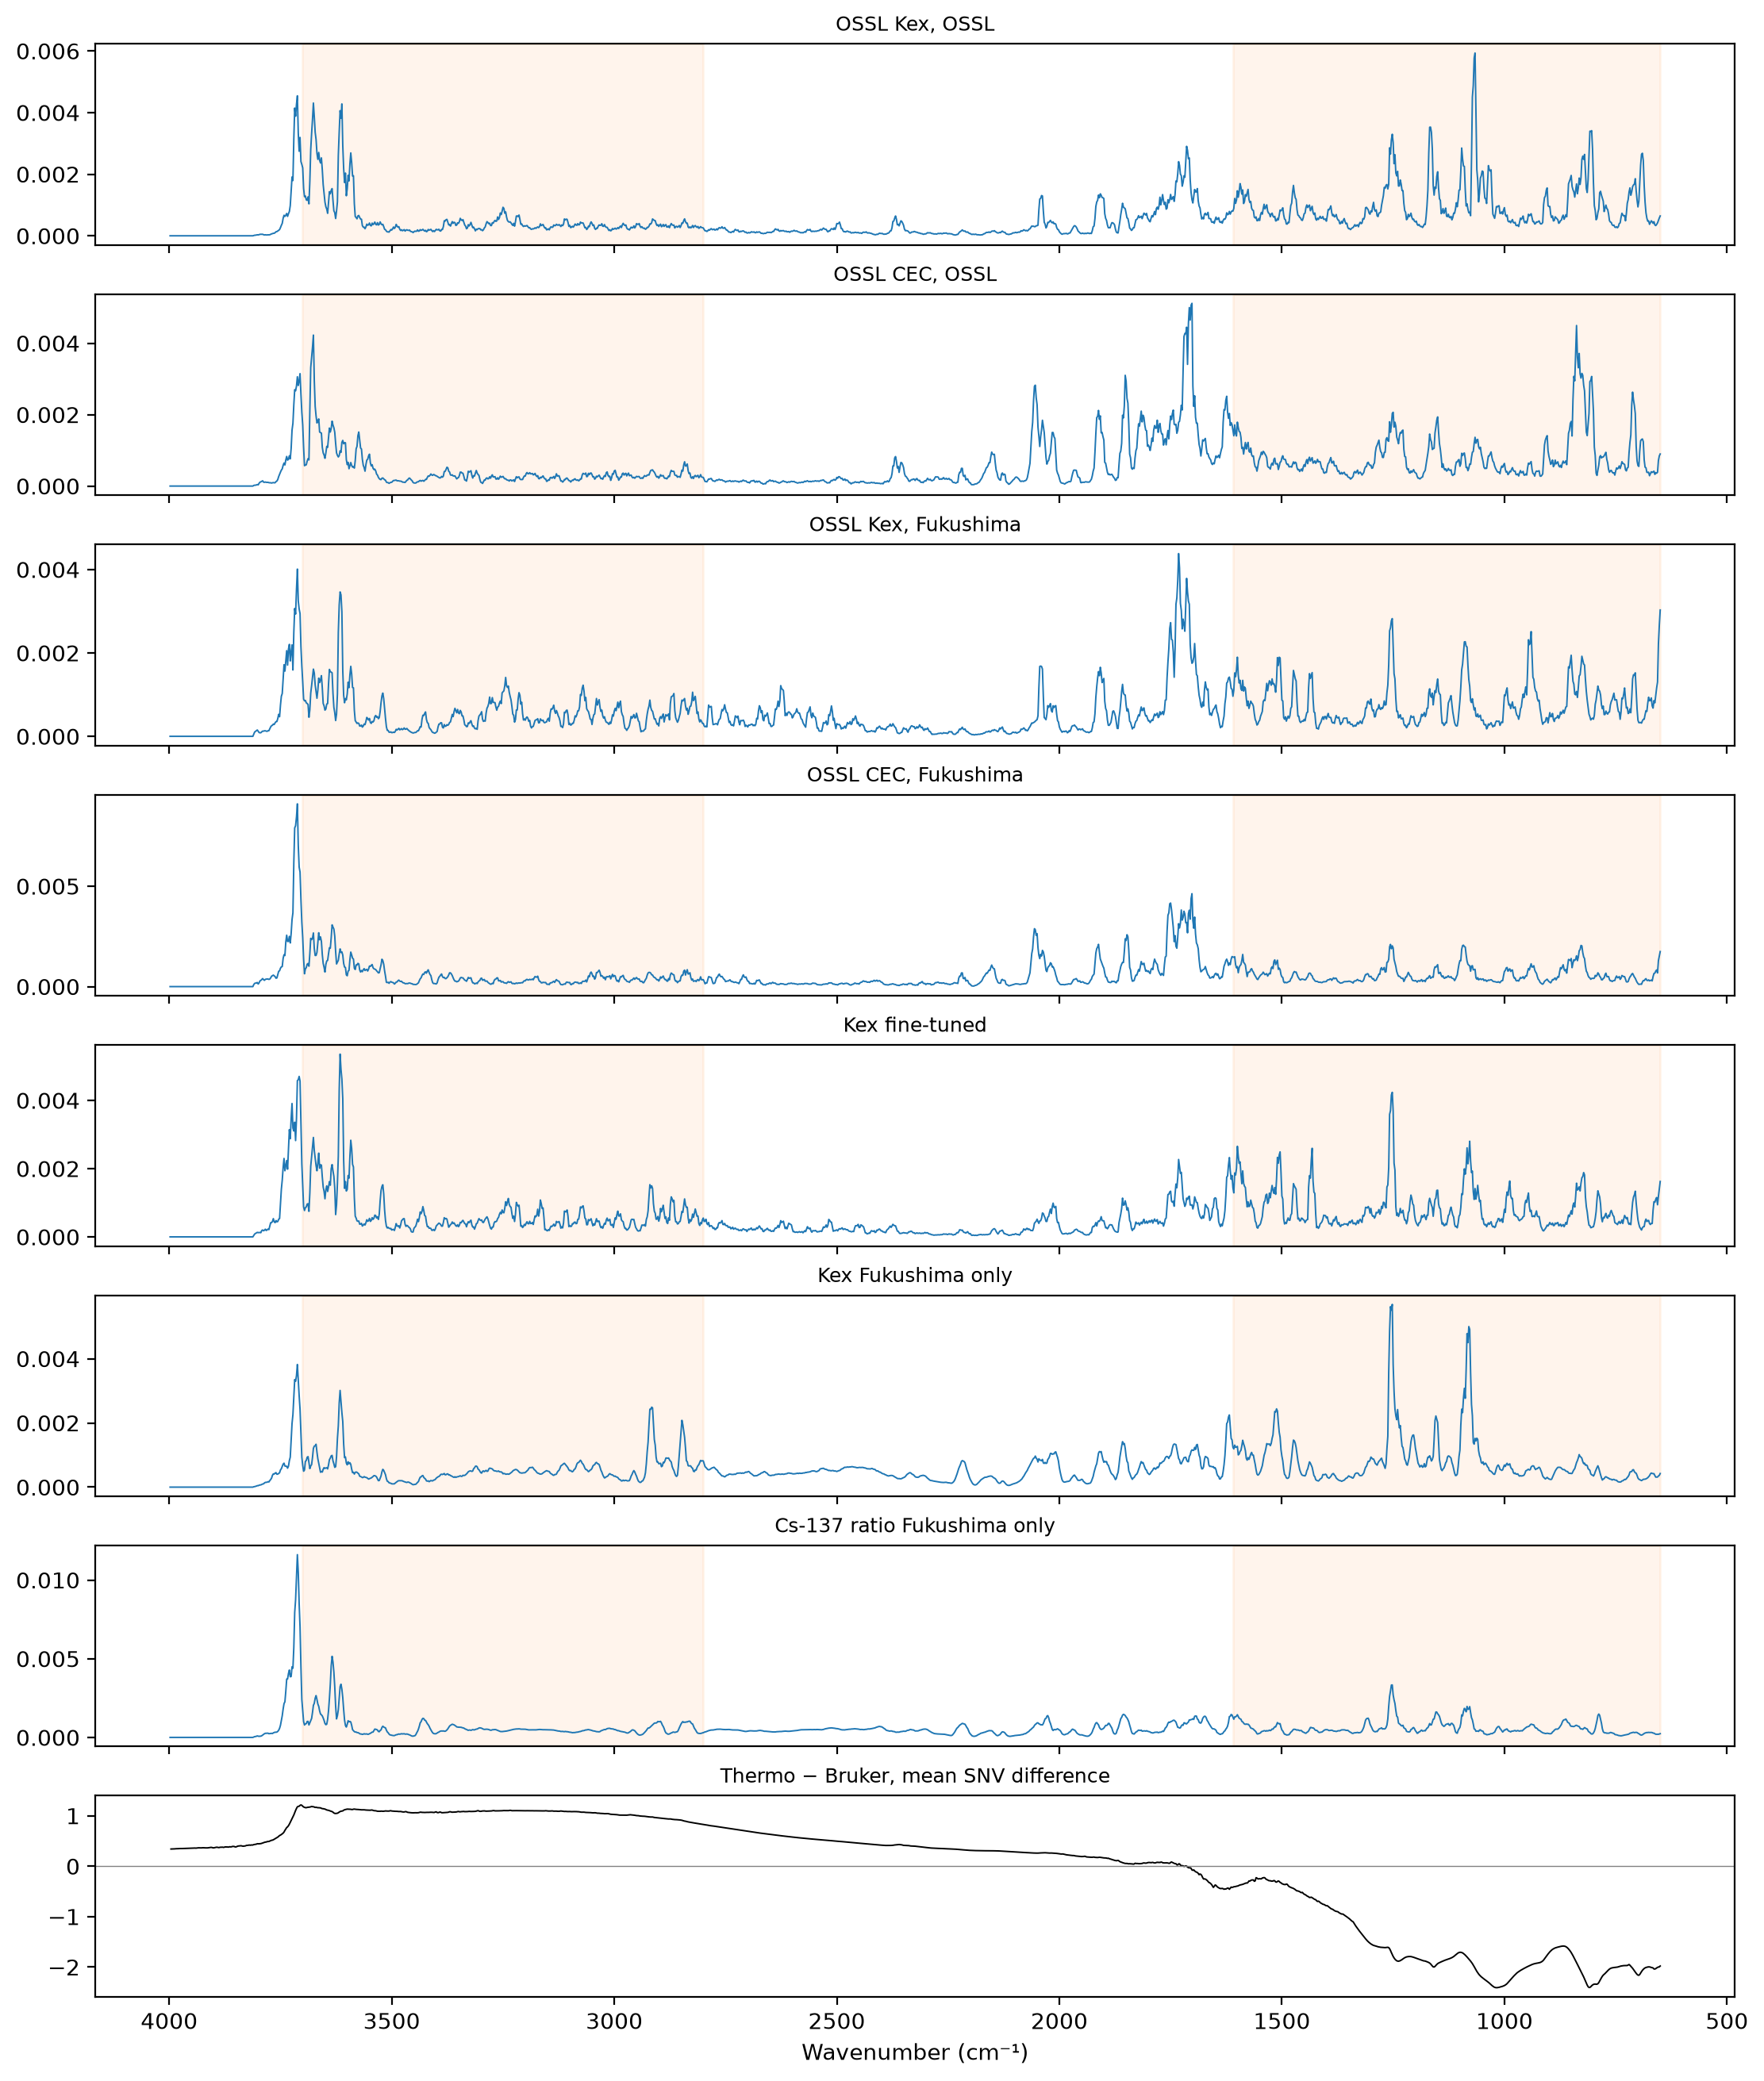

In [ ]:
#| fukudata
pw = shared_wns[:-1]
snv = lambda A: (A - A.mean(1, keepdims=True)) / A.std(1, keepdims=True)
pids = [i for i in sorted(set(bruker_files()) & set(spa_files()), key=int) if i not in excluded]
p_tb = (snv(load_fuku(pw, pids).spectra) - snv(load_bruker(pw, pids).spectra)).mean(0)
fig, axs = plt.subplots(len(mean_prof.columns) + 1, 1, figsize=(11, 13), sharex=True, layout='constrained')
for ax, c in zip(axs, mean_prof):
    ax.plot(shared_wns, mean_prof[c], lw=0.7); ax.set_title(c, fontsize=9)
    for lo, hi in [(2800, 3700), (650, 1610)]: ax.axvspan(lo, hi, color='tab:orange', alpha=0.08)
axs[-1].plot(pw, p_tb, lw=0.7, c='k'); axs[-1].axhline(0, c='grey', lw=0.5); axs[-1].set_title('Thermo − Bruker, mean SNV difference', fontsize=9)
axs[-1].invert_xaxis(); axs[-1].set_xlabel('Wavenumber (cm⁻¹)');

The share of each profile in each region, with the regions of `17_importance`, and the share in the two artefact regions, 2800–3700 cm⁻¹ and 650–1610 cm⁻¹:

In [ ]:
#| fukudata
regions = {'650–1300': (650, 1300), '1300–2000': (1300, 2000), '2000–2800': (2000, 2800), '2800–3200': (2800, 3200),
           '3200–3600': (3200, 3600), '3600–3700': (3600, 3700), '3700–3998': (3700, 3998)}
art = {'artefact, 2800–3700': (2800, 3700), 'artefact, 650–1610': (650, 1610)}
mean_raw = pd.DataFrame({c: prof[c] for c in list(prof.columns)[:4]} | {k: prof[[f'{k}, seed {s}' for s in range(3)]].mean(axis=1) for k in kinds})
pd.DataFrame({c: region_shares(mean_raw[c], shared_wns, regions | art) for c in mean_raw}).T.round(3)

,650–1300,1300–2000,2000–2800,2800–3200,3200–3600,3600–3700,3700–3998,"artefact, 2800–3700","artefact, 650–1610"
"OSSL Kex, OSSL",0.379,0.258,0.068,0.063,0.083,0.102,0.051,0.246,0.494
"OSSL CEC, OSSL",0.297,0.356,0.114,0.057,0.062,0.073,0.045,0.191,0.401
"OSSL Kex, Fukushima",0.268,0.291,0.124,0.103,0.093,0.062,0.061,0.257,0.380
"OSSL CEC, Fukushima",0.207,0.312,0.123,0.076,0.090,0.082,0.111,0.247,0.291
Kex fine-tuned,0.262,0.258,0.088,0.106,0.110,0.098,0.082,0.312,0.399
Kex Fukushima only,0.280,0.248,0.175,0.128,0.073,0.051,0.049,0.251,0.393
Cs-137 ratio Fukushima only,0.203,0.207,0.178,0.097,0.093,0.094,0.130,0.283,0.287


## Occlusion

The rise in mean squared error when each 40 cm⁻¹ window of the test spectra is set to zero, for seed 0 of each model trained on Fukushima and for the OSSL models on Fukushima. The five windows that matter most:

In [ ]:
#| fukudata
def occ(m):
    y = yf[target[m]]
    ok = is_test & np.isfinite(y)
    return occlusion(models[m], Xf[ok], y[ok])
occ_ = {'OSSL Kex': occ('OSSL Kex'), 'OSSL CEC': occ('OSSL CEC')} | {k: occ((k, 0)) for k in kinds}
pd.DataFrame({k: d.nlargest(5, 'rise in MSE').wavenumber.round(0).to_numpy() for k, d in occ_.items()}, index=range(1, 6))

,OSSL Kex,OSSL CEC,Kex fine-tuned,Kex Fukushima only,Cs-137 ratio Fukushima only
1,3749.0,3709.0,3749.0,3709.0,3709.0
2,3629.0,1749.0,3629.0,1589.0,3749.0
3,2989.0,1869.0,3709.0,1509.0,3669.0
4,1389.0,1709.0,1389.0,829.0,3629.0
5,1509.0,3749.0,1509.0,1229.0,1109.0


## Findings

The differences between models are larger than the differences between seeds. Over three seeds, the smoothed profiles of one model correlate at 0.97 (Kex fine-tuned), 0.86 (Kex trained on Fukushima only) and 0.93 (Cs-137 ratio trained on Fukushima only). Between models, the correlations are 0.43 to 0.80.

The Cs-137 ratio model, the one that predicts best on new fields, looks most like the OSSL CEC model on the Fukushima spectra (0.78) and the fine-tuned Kex model (0.73). It looks less like the Kex model trained on Fukushima only (0.61) and the OSSL Kex model on OSSL (0.53). Compared with the OSSL Kex model on OSSL, it gives less weight to 650–1300 cm⁻¹ (20% against 38%) and more to 2000–2800 cm⁻¹ (18% against 7%) and 3700–3998 cm⁻¹ (13% against 5%).

By occlusion, the models share one region. For every model run on the Fukushima spectra, the most important 40 cm⁻¹ window is centred at 3709 or 3749 cm⁻¹. For the Cs-137 ratio model, four of the five most important windows lie between 3629 and 3749 cm⁻¹, the clay-mineral O–H region. The fine-tuned Kex model has three of its five there. The Kex model trained on Fukushima only has one, and its other windows lie at 1589, 1509, 829 and 1229 cm⁻¹. The OSSL Kex model on OSSL also ranks 3749 and 3629 cm⁻¹ first and second. So the models that predict best, the Cs-137 ratio model and the OSSL Kex model on OSSL, both depend most on the clay-mineral O–H region, and the Kex model trained on Fukushima, which predicts worst, depends on it least.

The windows at 3709 and 3749 cm⁻¹ lie at the upper edge of the IAEA artefact, where the Thermo − Bruker difference falls from about 1.1 to 0.5 after SNV (`21_iaea`). The models trained on Fukushima do not lean on the artefact regions more than the OSSL models do on OSSL: 25% to 31% of their importance lies in 2800–3700 cm⁻¹, against 25% for the OSSL Kex model on OSSL. `21_iaea` found that removing the artefact does not change the scores of models trained on Fukushima, so the artefact is unlikely to be what these windows pick up. That is an inference, not a test.

The test scores of this notebook use the Cs-137 study's split, which shares fields, and they are optimistic. Integrated gradients from a flat spectrum of zeros are one choice of baseline among several.